In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Step 1:
   - Load Data and clean for Training

In [2]:
data = pd.read_csv('student_habits_performance.csv')

In [3]:
data.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [4]:
data.shape

(1000, 16)

In [5]:
data.duplicated(subset=['student_id']).sum()

np.int64(0)

In [6]:
data.isna().sum()

student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

In [7]:
data.dropna(subset=['parental_education_level'], inplace=True)

In [8]:
data.columns

Index(['student_id', 'age', 'gender', 'study_hours_per_day',
       'social_media_hours', 'netflix_hours', 'part_time_job',
       'attendance_percentage', 'sleep_hours', 'diet_quality',
       'exercise_frequency', 'parental_education_level', 'internet_quality',
       'mental_health_rating', 'extracurricular_participation', 'exam_score'],
      dtype='object')

In [9]:
print(f"Gender = {data.gender.unique()}") #Now this gender column has 3 nominal ceatogry so we encode this by using one-hot-encoding

Gender = ['Female' 'Male' 'Other']


In [10]:
print(f"""Part_time_job = {data.part_time_job.unique()},
extracurricular_participation = {data.extracurricular_participation.unique()}""") 
#Now this columns has 2 nominal ceatogry so we can enncode this by using lable-encoding

Part_time_job = ['No' 'Yes'],
extracurricular_participation = ['Yes' 'No']


In [11]:
print(f"""Diet Quality = {data.diet_quality.unique()}, 
Parent_Education_Level = {data.parental_education_level.unique()},
Internet Quality = {data.internet_quality.unique()}""") #Now these all columns has ordinal cateogrical data so we can encode this 
#by using ordinal-encoding

Diet Quality = ['Fair' 'Good' 'Poor'], 
Parent_Education_Level = ['Master' 'High School' 'Bachelor'],
Internet Quality = ['Average' 'Poor' 'Good']


# Step 2: Data Processing

### One-Hot-Encoding

In [12]:
import sklearn
from sklearn.preprocessing import OneHotEncoder

In [13]:
ohe = OneHotEncoder( sparse_output=False, handle_unknown='ignore')

In [14]:
ohe.set_output(transform="pandas")

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [15]:
ohg = ohe.fit_transform(data[['gender']]).astype(int)

### Lable-Encoding

In [16]:
from sklearn.preprocessing import LabelEncoder

In [17]:
lable_encoder_ptj = LabelEncoder()
lable_encoder_ep = LabelEncoder()

In [18]:
lben = pd.DataFrame({'part_time_job':lable_encoder_ptj.fit_transform(data['part_time_job']),'extracurricular_participation':lable_encoder_ep.fit_transform(data['extracurricular_participation']) })

In [19]:
ohg = ohg.reset_index(drop=True)
lben = lben.reset_index(drop=True)
ohg[['part_time_job','extracurricular_participation']] = lben
ohg.head(3)

,gender_Female,gender_Male,gender_Other,part_time_job,extracurricular_participation
0,1,0,0,0,1
1,1,0,0,0,0
2,0,1,0,0,0


### Ordinal-Encoding

In [20]:
from sklearn.preprocessing import OrdinalEncoder

In [21]:
order = [
    ['Poor','Fair', 'Good'],
    ['High School', 'Bachelor' ,'Master'],
    ['Poor' , 'Average' , 'Good']
]

In [22]:
ode = OrdinalEncoder(categories=order, handle_unknown='use_encoded_value', unknown_value=-1)

In [23]:
ode.set_output(transform='pandas')
oder = ode.fit_transform(data[['diet_quality','parental_education_level','internet_quality']]).astype(int).reset_index(drop=True)

In [24]:
ohg[['diet_quality','parental_education_level','internet_quality']] = oder

In [25]:
df = data.copy()
df.drop(labels=['gender','part_time_job','student_id', 'extracurricular_participation','diet_quality','parental_education_level','internet_quality'], axis=1, inplace=True)
df = df.reset_index(drop=True)
process_data = pd.concat([ohg,df], axis=1)

In [26]:
process_data.head() #Now our data is cleaned and procees by encoding and it is ready for feeding the Regression-Model

,gender_Female,gender_Male,gender_Other,part_time_job,extracurricular_participation,diet_quality,parental_education_level,internet_quality,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
0,1,0,0,0,1,1,2,1,23,0.0,1.2,1.1,85.0,8.0,6,8,56.2
1,1,0,0,0,0,2,0,1,20,6.9,2.8,2.3,97.3,4.6,6,8,100.0
2,0,1,0,0,0,0,0,0,21,1.4,3.1,1.3,94.8,8.0,1,1,34.3
3,1,0,0,0,1,0,2,2,23,1.0,3.9,1.0,71.0,9.2,4,1,26.8
4,1,0,0,0,0,1,2,2,19,5.0,4.4,0.5,90.9,4.9,3,1,66.4


# Step 3: Comparing Correlation between output and input

In [27]:
process_data.corr()['exam_score']

gender_Female                    0.023693
gender_Male                     -0.033658
gender_Other                     0.025572
part_time_job                   -0.016917
extracurricular_participation    0.003446
diet_quality                     0.013793
parental_education_level        -0.021093
internet_quality                -0.038697
age                             -0.012833
study_hours_per_day              0.822950
social_media_hours              -0.171672
netflix_hours                   -0.166578
attendance_percentage            0.096005
sleep_hours                      0.122294
exercise_frequency               0.161397
mental_health_rating             0.317945
exam_score                       1.000000
Name: exam_score, dtype: float64

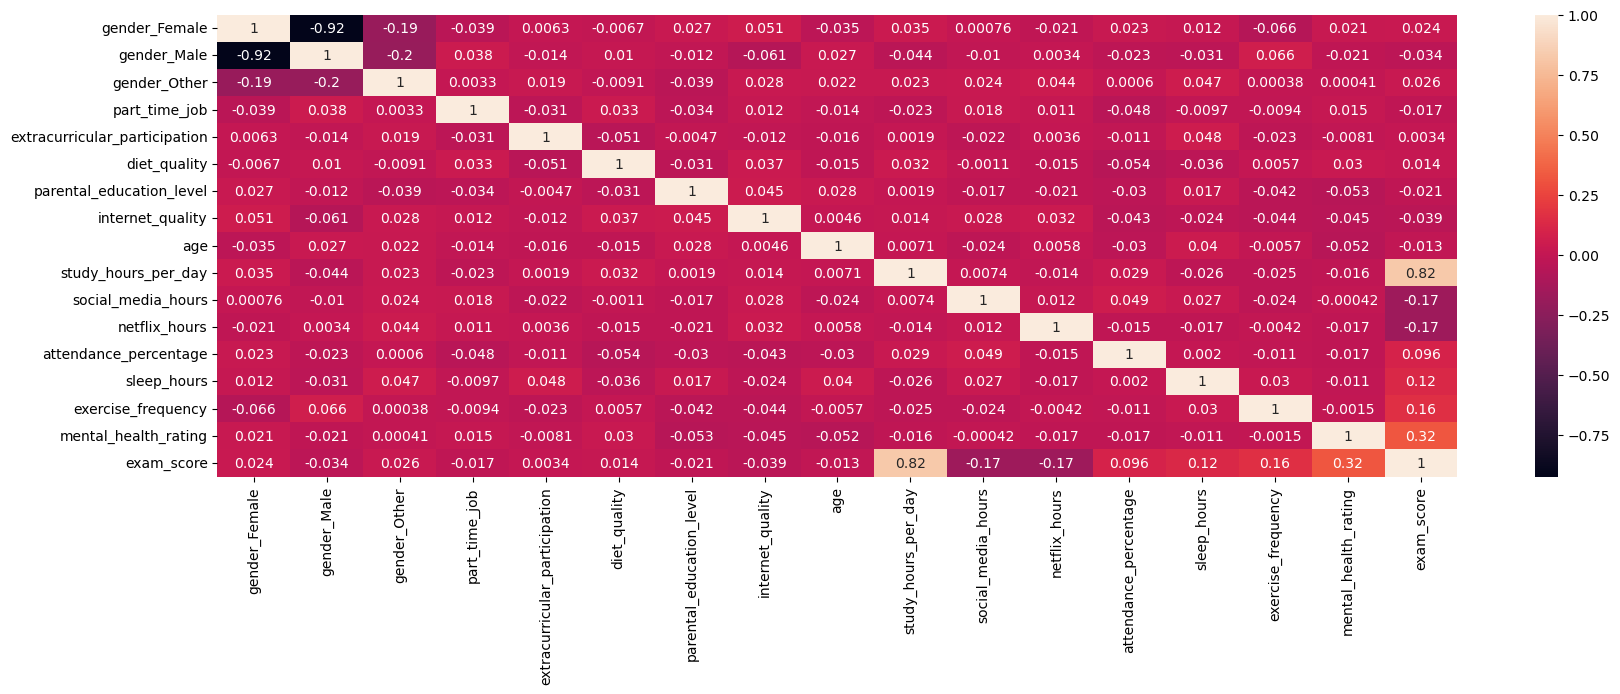

In [28]:
plt.figure(figsize=(20,6))
sns.heatmap(process_data.corr(), annot=True)
plt.show()

In [29]:
# In the above coorelation we can clearly see thath these columns ['study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 
#'exercise_frequency', 'mental_health_rating']  making strong coorelation with exam score however the ['attendance_percentage'] making moderate
#coorelation wich is bad but for exam_score 'attendance_percentage' is making affect in real world so we add this column too

# Step 4: Making X and y variable then Split data into Training and Testing sets

### Making X(input) AND y(output)

In [30]:
X = process_data[['study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 'exercise_frequency', 'mental_health_rating', 'attendance_percentage']]

In [31]:
y = process_data['exam_score']

### Spliting Data

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

# Step 5: Training model by giving training input(X) and output(y)

In [34]:
from sklearn.linear_model import LinearRegression

In [35]:
lr = LinearRegression()

In [36]:
lr.fit(x_train,y_train)

LinearRegression()

In [37]:
lr.coef_,  lr.intercept_

(array([ 9.60657019, -2.64737739, -2.15063337,  2.02405179,  1.52098578,
         1.98765279,  0.17119861]),
 np.float64(3.1637999678914923))

# Step 6: Testing Model and Model Evaluation

In [38]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error, mean_absolute_error

### Testing on training data

In [39]:
x_train_predict = lr.predict(x_train)

In [41]:
print(f"""R2_Score = {r2_score(y_train,x_train_predict)}
MSE      = {mean_squared_error(y_train,x_train_predict)}
RMSE     = {root_mean_squared_error(y_train,x_train_predict)}
MAE      = {mean_absolute_error(y_train,x_train_predict)}""")        #our model is 89% accurate which is good

R2_Score = 0.9016927038303326
MSE      = 28.44825624601236
RMSE     = 5.3336906777589155
MAE      = 4.23277565712013


In [42]:
pd.DataFrame({'Original_Data':y_train, 'Prediction':x_train_predict}).head()

,Original_Data,Prediction
84,73.4,76.567229
10,74.4,62.193709
617,59.8,57.357374
250,63.0,68.901015
870,100.0,108.225320


### Testing on Testing data

In [43]:
x_test_predict = lr.predict(x_test)

In [45]:
print(f"""R2_Score = {r2_score(y_test, x_test_predict)}
MSE      = {mean_squared_error(y_test, x_test_predict)} 
RMSE     = {root_mean_squared_error(y_test, x_test_predict)}
MAE      = {mean_absolute_error(y_test, x_test_predict)}""")         # our model is 88% accurate on testing data wich is good

R2_Score = 0.8897165427387149
MSE      = 29.934574276026847 
RMSE     = 5.471249791046543
MAE      = 4.222163023475247


In [46]:
pd.DataFrame({'Original_Data':y_test, 'Prediction':x_test_predict}).head()

,Original_Data,Prediction
866,59.6,61.954140
439,43.3,51.267883
342,68.4,70.755973
737,75.1,70.850447
786,87.9,87.493574


### Final Vedict:
This model is "Good Fit" model bcz the training score is 89% is which good but the twist is the testing score 
is 88% which is too close to the training score its mean the model is not underfit or overfit it's goodfit model